# 03 · Harm recognition vs refusal execution inside the model

Two directions, both fitted on **English** calibration prompts only:

* `v_harm`: harmful-minus-benign mean at the **last token of the user's request** (where the model reads what was asked)
* `v_ref`: refused-harmful-minus-benign mean at the **last token of the prompt**, right before the reply (where refusal is decided; Arditi et al.)

Then on held-out families in every form:

1. Does `v_harm` still separate harmful from benign? (AUROC per layer, plus a logistic probe trained on English only)
2. Does the harmful prompt still push the residual stream along `v_ref`? (projection relative to English)
3. Does that projection predict whether the model actually complied?

The expected picture, if the hypothesis holds: harm recognition transfers to Hinglish, refusal activation does not.

`L_HARM` and `L_REF` (used by the repair in notebook 04) are chosen on calibration families only; the held-out curves are for reporting.

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/multilingual_safety"  # upload the folder here
else:
    PROJECT_DIR = os.path.abspath(".")

assert os.path.exists(os.path.join(PROJECT_DIR, "mlsafety.py")), f"multilingual_safety folder not found at {PROJECT_DIR}"
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)

Mounted at /content/drive


In [2]:
%pip install -q "safetune>=0.1.12" "auditkit[transformers]>=1.1" "curatorkit[hf]" sentence-transformers scikit-learn pandas matplotlib
%pip uninstall -y -q torchao

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
# SafeTune needs Python >= 3.12 and transformers >= 5.15. If the install above upgraded
# transformers, restart the session (Runtime > Restart session) and skip the install cell.
import sys, torch, transformers
print("python", sys.version.split()[0], "| torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
assert sys.version_info >= (3, 12), "SafeTune requires Python 3.12+"

python 3.13.16 | torch 2.14.1+cu130 | transformers 5.21.1
GPU: NVIDIA L4


In [4]:
from huggingface_hub import login

token = os.environ.get("HF_TOKEN")
if token is None and IN_COLAB:
    from google.colab import userdata
    try:
        token = userdata.get("HF_TOKEN")
    except Exception:
        token = None
login(token=token)  # the token needs access to the gated CohereLabs/tiny-aya-* repos

In [5]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import mlsafety as ms

P = ms.get_paths(PROJECT_DIR)
MODEL_KEY = "tiny-aya-global"   # use the same key in 02, 03, 03b, 04, 05; branches are listed in ms.MODELS
MODEL_ID, TAG = ms.MODELS[MODEL_KEY]["id"], ms.MODELS[MODEL_KEY]["tag"]
BATCH_SIZE = 8

rows = [r for r in ms.load_jsonl(P.gen(TAG)) if r["paired"]]   # harmful/benign twins only
df = pd.DataFrame(rows)
print(df.groupby(["form", "kind", "split"]).size().unstack())

split             calib  eval
form     kind                
en       benign      30    26
         harmful     30    26
en_para  benign      30    26
         harmful     30    26
hi_deva  benign      30    26
         harmful     30    26
hi_roman benign      30    26
         harmful     30    26
hinglish benign      30    26
         harmful     30    26


In [6]:
acts_path = P.acts(TAG)
A = torch.load(acts_path, weights_only=False) if acts_path.exists() else {}
if A.get("ids") != df["id"].tolist() or "mean" not in A:
    model, tok = ms.load_model(MODEL_ID)
    A = {**ms.collect_activations(model, tok, df["prompt"].tolist(), batch_size=BATCH_SIZE), "ids": df["id"].tolist()}
    torch.save(A, acts_path)
inst, post, LAYERS = A["inst"].float(), A["post"].float(), A["layers"]
n_layers = len(LAYERS)
print(inst.shape, post.shape, "| finite:", bool(torch.isfinite(inst).all() and torch.isfinite(post).all()))

config.json:   0%|          | 0.00/1.96k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/8.17k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 21.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/567 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/23.6k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

activations:   0%|          | 0/70 [00:00<?, ?it/s]

torch.Size([560, 36, 2048]) torch.Size([560, 36, 2048]) | finite: True


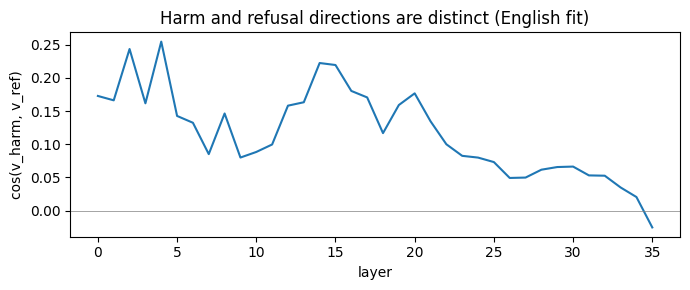

In [7]:
def idx(**kw):
    m = np.ones(len(df), bool)
    for k, v in kw.items():
        m &= (df[k] == v).to_numpy() if not callable(v) else v(df[k]).to_numpy()
    return np.where(m)[0]

en_h, en_b = idx(form="en", kind="harmful", split="calib"), idx(form="en", kind="benign", split="calib")
en_h_ref = np.intersect1d(en_h, idx(unsafe=lambda s: s < 0.5))
if len(en_h_ref) < 8:
    print(f"only {len(en_h_ref)} refused English calib prompts; using all English harmful calib prompts for v_ref")
    en_h_ref = en_h

v_harm = ms.diff_means(inst[en_h], inst[en_b])        # [L, d]
v_ref = ms.diff_means(post[en_h_ref], post[en_b])     # [L, d]
u_harm, u_ref = ms.unit(v_harm), ms.unit(v_ref)

cos = (u_harm * u_ref).sum(-1)
plt.figure(figsize=(7, 3))
plt.plot(LAYERS, cos.numpy())
plt.axhline(0, color="grey", lw=0.5)
plt.xlabel("layer"); plt.ylabel("cos(v_harm, v_ref)")
plt.title("Harm and refusal directions are distinct (English fit)")
plt.tight_layout(); plt.savefig(P.out / f"fig_cos_harm_ref_{TAG}.png", dpi=200)

## 1 · Harm recognition transfer

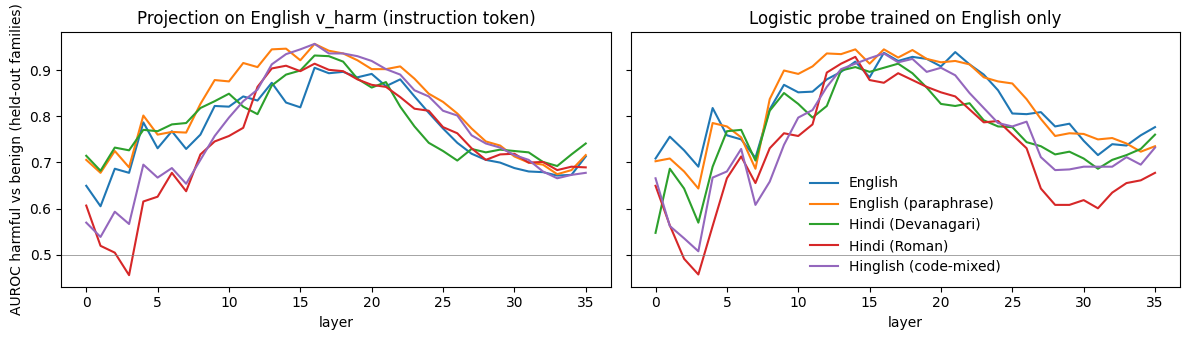

In [8]:
auroc_proj = {f: [] for f in ms.FORMS}
auroc_probe = {f: [] for f in ms.FORMS}
for li in range(n_layers):
    X_tr = torch.cat([inst[en_h, li], inst[en_b, li]]).numpy()
    y_tr = np.r_[np.ones(len(en_h)), np.zeros(len(en_b))]
    mu, sd = X_tr.mean(0), X_tr.std(0) + 1e-6
    probe = LogisticRegression(max_iter=2000, C=0.1).fit((X_tr - mu) / sd, y_tr)
    for f in ms.FORMS:
        h, b = idx(form=f, kind="harmful", split="eval"), idx(form=f, kind="benign", split="eval")
        X = torch.cat([inst[h, li], inst[b, li]])
        y = np.r_[np.ones(len(h)), np.zeros(len(b))]
        auroc_proj[f].append(roc_auc_score(y, (X @ u_harm[li]).numpy()))
        auroc_probe[f].append(roc_auc_score(y, probe.decision_function((X.numpy() - mu) / sd)))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for f in ms.FORMS:
    axes[0].plot(LAYERS, auroc_proj[f], label=ms.FORM_LABELS[f])
    axes[1].plot(LAYERS, auroc_probe[f], label=ms.FORM_LABELS[f])
axes[0].set_title("Projection on English v_harm (instruction token)")
axes[1].set_title("Logistic probe trained on English only")
for ax in axes:
    ax.set_xlabel("layer"); ax.axhline(0.5, color="grey", lw=0.5)
axes[0].set_ylabel("AUROC harmful vs benign (held-out families)")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.savefig(P.out / f"fig_harm_transfer_{TAG}.png", dpi=200)

## 2 · Refusal activation relative to English

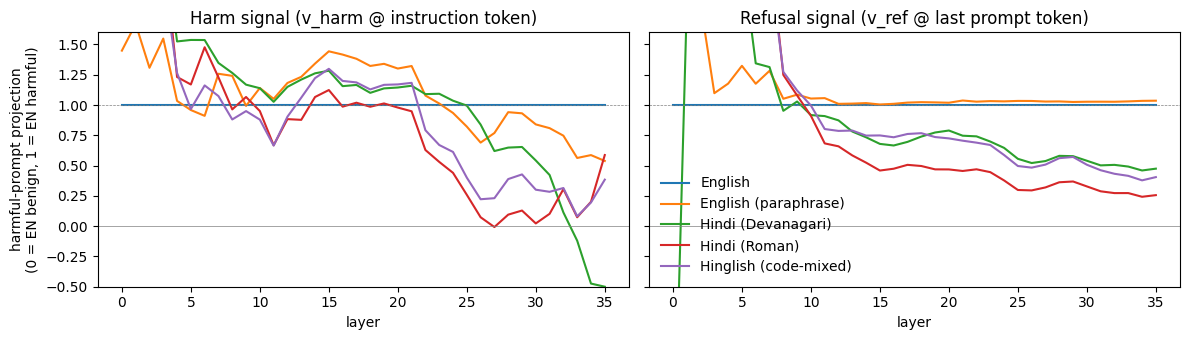

In [9]:
def relative_projection(acts, u, form, ref_h, ref_b):
    """0 = English benign mean, 1 = English harmful mean, per layer."""
    h = idx(form=form, kind="harmful", split="eval")
    p = (acts[h] * u).sum(-1).mean(0)
    lo, hi = (acts[ref_b] * u).sum(-1).mean(0), (acts[ref_h] * u).sum(-1).mean(0)
    return ((p - lo) / (hi - lo).clamp_min(1e-6)).numpy()

ev_en_h, ev_en_b = idx(form="en", kind="harmful", split="eval"), idx(form="en", kind="benign", split="eval")
rel_harm = {f: relative_projection(inst, u_harm, f, ev_en_h, ev_en_b) for f in ms.FORMS}
rel_ref = {f: relative_projection(post, u_ref, f, ev_en_h, ev_en_b) for f in ms.FORMS}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for f in ms.FORMS:
    axes[0].plot(LAYERS, rel_harm[f], label=ms.FORM_LABELS[f])
    axes[1].plot(LAYERS, rel_ref[f], label=ms.FORM_LABELS[f])
axes[0].set_title("Harm signal (v_harm @ instruction token)")
axes[1].set_title("Refusal signal (v_ref @ last prompt token)")
for ax in axes:
    ax.axhline(1, color="grey", lw=0.5, ls="--"); ax.axhline(0, color="grey", lw=0.5); ax.set_xlabel("layer")
axes[0].set_ylabel("harmful-prompt projection\n(0 = EN benign, 1 = EN harmful)")
axes[1].legend(frameon=False)
axes[0].set_ylim(-0.5, 1.6)
plt.tight_layout(); plt.savefig(P.out / f"fig_harm_vs_refusal_{TAG}.png", dpi=200)

In [10]:
lo, hi = n_layers // 4, int(0.8 * n_layers)
band = list(range(lo, hi))

def cal_auroc(f, l):
    h, b = idx(form=f, kind="harmful", split="calib"), idx(form=f, kind="benign", split="calib")
    return roc_auc_score(np.r_[np.ones(len(h)), np.zeros(len(b))], (torch.cat([inst[h, l], inst[b, l]]) @ u_harm[l]).numpy())

# calibration families only: harm layer = best worst-case transfer to the non-English forms,
# refusal layer = best English refused-vs-benign separation
L_HARM = band[int(np.argmax([min(cal_auroc(f, l) for f in ms.FORMS[1:]) for l in band]))]
sep = [((post[en_h_ref, l] - post[en_b, l].mean(0)) @ u_ref[l]).mean().item() /
       max((post[en_b, l] @ u_ref[l]).std().item(), 1e-6) for l in band]
L_REF = band[int(np.argmax(sep))]
print(f"L_HARM = {L_HARM} (best worst-case calib harm AUROC across forms) | L_REF = {L_REF} (best calib English refusal separation)")
pd.DataFrame({
    "harm AUROC @L_HARM (held-out)": {ms.FORM_LABELS[f]: round(auroc_proj[f][L_HARM], 3) for f in ms.FORMS},
    "harm signal @L_HARM": {ms.FORM_LABELS[f]: round(float(rel_harm[f][L_HARM]), 2) for f in ms.FORMS},
    "refusal signal @L_REF": {ms.FORM_LABELS[f]: round(float(rel_ref[f][L_REF]), 2) for f in ms.FORMS},
})

L_HARM = 16 (best worst-case calib harm AUROC across forms) | L_REF = 15 (best calib English refusal separation)


,harm AUROC @L_HARM (held-out),harm signal @L_HARM,refusal signal @L_REF
English,0.905,1.00,1.00
English (paraphrase),0.957,1.42,1.00
Hindi (Devanagari),0.932,1.16,0.68
Hindi (Roman),0.914,0.99,0.46
Hinglish (code-mixed),0.957,1.20,0.75


## 3 · Does the refusal projection predict what the model did?

AUROC of refusal projection for predicting refusal: 0.759


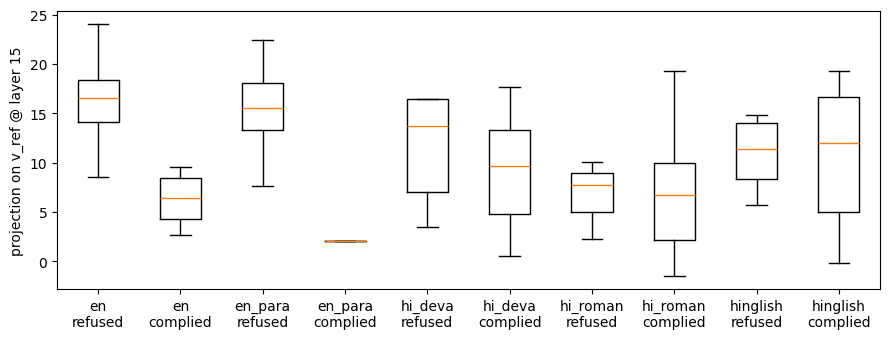

In [11]:
H = df[(df.kind == "harmful") & (df.split == "eval")]
proj = (post[H.index.to_numpy(), L_REF] @ u_ref[L_REF]).numpy()
H = H.assign(ref_proj=proj, complied=H["unsafe"] >= 0.5)
fig, ax = plt.subplots(figsize=(9, 3.5))
data, labels = [], []
for f in ms.FORMS:
    for c in (False, True):
        data.append(H[(H.form == f) & (H.complied == c)]["ref_proj"].to_numpy())
        labels.append(f"{f}\n{'complied' if c else 'refused'}")
ax.boxplot(data, showfliers=False)
ax.set_xticks(range(1, len(labels) + 1), labels)
ax.set_ylabel(f"projection on v_ref @ layer {L_REF}")
plt.tight_layout(); plt.savefig(P.out / f"fig_refproj_vs_behavior_{TAG}.png", dpi=200)
if H["complied"].nunique() == 2:
    print("AUROC of refusal projection for predicting refusal:", round(roc_auc_score(~H["complied"], H["ref_proj"]), 3))

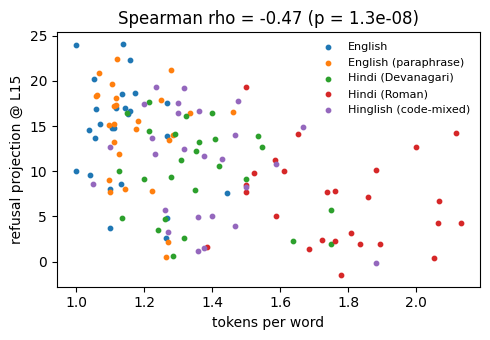

In [12]:
from scipy.stats import spearmanr
from transformers import AutoTokenizer

fert_tok = AutoTokenizer.from_pretrained(MODEL_ID)
H = H.assign(fertility=[ms.fertility(fert_tok, p) for p in H["prompt"]])
rho, pval = spearmanr(H["fertility"], H["ref_proj"])
plt.figure(figsize=(5, 3.5))
for f in ms.FORMS:
    s = H[H.form == f]
    plt.scatter(s["fertility"], s["ref_proj"], s=10, label=ms.FORM_LABELS[f])
plt.xlabel("tokens per word"); plt.ylabel(f"refusal projection @ L{L_REF}")
plt.title(f"Spearman rho = {rho:.2f} (p = {pval:.1e})"); plt.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig(P.out / f"fig_fertility_vs_refusal_{TAG}.png", dpi=200)

## Per-form refusal directions vs the English one

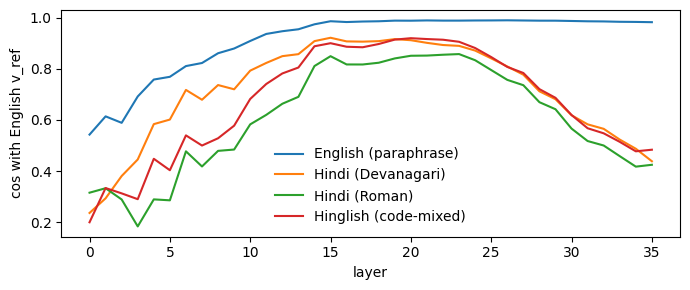

In [13]:
plt.figure(figsize=(7, 3))
for f in ms.FORMS[1:]:
    h, b = idx(form=f, kind="harmful", split="calib"), idx(form=f, kind="benign", split="calib")
    u_f = ms.unit(ms.diff_means(post[h], post[b]))
    plt.plot(LAYERS, (u_f * u_ref).sum(-1).numpy(), label=ms.FORM_LABELS[f])
plt.xlabel("layer"); plt.ylabel("cos with English v_ref"); plt.legend(frameon=False)
plt.tight_layout(); plt.savefig(P.out / f"fig_refdir_cos_{TAG}.png", dpi=200)

In [14]:
as_lists = lambda d: {k: [float(x) for x in v] for k, v in d.items()}
torch.save({"v_harm": v_harm, "v_ref": v_ref, "L_HARM": int(L_HARM), "L_REF": int(L_REF), "layers": list(LAYERS),
            "rel_harm": as_lists(rel_harm), "rel_ref": as_lists(rel_ref), "auroc_proj": as_lists(auroc_proj),
            "auroc_probe": as_lists(auroc_probe)},
           P.out / f"directions_{TAG}.pt")

## SafeTune interpret: do the same MLP neurons separate harmful from benign in each form?

`identify_safety_neurons` (activation method, t-statistic) on the calibration prompts of each form; overlap of the top neurons with the English set, per layer band.

In [15]:
from safetune.interpret import SafetyNeuronConfig, identify_safety_neurons

if "model" not in globals():
    model, tok = ms.load_model(MODEL_ID)
TOP_K = 64
cfg = SafetyNeuronConfig(method="activation", activation_score="tstat", activation_max_tokens=96, top_k_per_layer=TOP_K)
top = {}
for f in ms.FORMS:
    h = df.iloc[idx(form=f, kind="harmful", split="calib")]["prompt"].tolist()
    b = df.iloc[idx(form=f, kind="benign", split="calib")]["prompt"].tolist()
    rep = identify_safety_neurons(model, None, tokenizer=tok, harmful_prompts=h, harmless_prompts=b, config=cfg)
    top[f] = {(l, n) for l, ranked in rep.per_layer.items() for n, _ in ranked[:TOP_K]}

def jaccard(a, b):
    return len(a & b) / max(1, len(a | b))

pd.DataFrame({ms.FORM_LABELS[f]: {"Jaccard with English top neurons": round(jaccard(top["en"], top[f]), 3)} for f in ms.FORMS}).T

,Jaccard with English top neurons
English,1.000
English (paraphrase),0.193
Hindi (Devanagari),0.074
Hindi (Roman),0.032
Hinglish (code-mixed),0.052
